# Experiment 6: Implementation of SVM

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training samples:", len(X_train), "Testing samples:", len(X_test))

Training samples: 455 Testing samples: 114


In [3]:
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train, y_train)
pred_linear = svm_linear.predict(X_test)

svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train, y_train)
pred_rbf = svm_rbf.predict(X_test)

print("Linear Kernel Accuracy:", round(accuracy_score(y_test, pred_linear), 4))
print("RBF Kernel Accuracy:", round(accuracy_score(y_test, pred_rbf), 4))

Linear Kernel Accuracy: 0.9561
RBF Kernel Accuracy: 0.9825


In [4]:
cm = confusion_matrix(y_test, pred_rbf)
print("Confusion Matrix (RBF):")
print(cm)
print("Classification Report (RBF):")
print(classification_report(y_test, pred_rbf))

Confusion Matrix (RBF):
[[41  2]
 [ 0 71]]
Classification Report (RBF):
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        43
           1       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



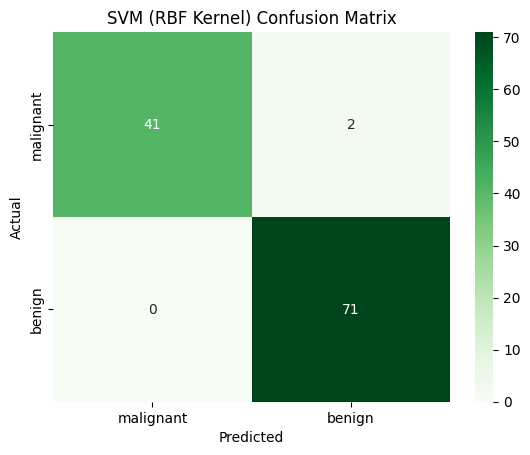

In [5]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=data.target_names, yticklabels=data.target_names)
plt.title('SVM (RBF Kernel) Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()